# Assignment 2: Data Wrangling with Pandas #
**Name:** Mehmet Ali TARIM 

**Student ID:** 0095611 

**Date:** 06.11.2026

### TASK-1 Load and merge. 
Reshape the three files to long format and merge them into one country–year table. Add a continent classification from a source you cite, and report the countries that fail to match

In [67]:
import pandas as pd
import numpy as np

gdp = pd.read_csv('/dosyalar/rhymecoholic/mali/10_Kaynaklar/Master/KOC/CSSM_502/Datasets/gapminder/gdp_pcap.csv')
life = pd.read_csv('/dosyalar/rhymecoholic/mali/10_Kaynaklar/Master/KOC/CSSM_502/Datasets/gapminder/life_expectancy.csv')
population = pd.read_csv('/dosyalar/rhymecoholic/mali/10_Kaynaklar/Master/KOC/CSSM_502/Datasets/gapminder/population.csv')

# import edildi. hepsi wide format.

long_gdp = gdp.set_index('country').stack().reset_index()
long_gdp.columns = ['country', 'year', 'gdp']

long_life = life.set_index('country').stack().reset_index()
long_life.columns = ['country', 'year', 'life expectancy']

long_population = population.set_index('country').stack().reset_index()
long_population.columns = ['country', 'year', 'population']

# long formata çevirildi ve yeni column isimlerini verdim. ucunu tek seferde merge'leyemedigim icin sırayla eklicem:

merged = pd.merge(long_gdp, long_life, on=['country', 'year'], how='outer')
merged = pd.merge(merged, long_population, on=['country', 'year'], how= 'outer')

# continent kismi icin kaynak buldurdum LLM'e

iso_url = "https://raw.githubusercontent.com/lukes/ISO-3166-Countries-with-Regional-Codes/master/all/all.csv"
iso = pd.read_csv(iso_url)[['name', 'region']].rename(columns={'name': 'country', 'region': 'continent'})
merged = pd.merge(merged, iso, on= 'country', how='left')

# eslesmeyenler

unmatched = merged[merged['continent'].isnull()]['country'].unique()
print(unmatched)


<StringArray>
[                       'Bolivia',                         'Brunei',
                     'Cape Verde',               'Congo, Dem. Rep.',
                    'Congo, Rep.',                  'Cote d'Ivoire',
                 'Czech Republic',               'Hong Kong, China',
                           'Iran',                'Kyrgyz Republic',
                            'Lao',          'Micronesia, Fed. Sts.',
                        'Moldova',                    'Netherlands',
                    'North Korea',                      'Palestine',
                         'Russia',                'Slovak Republic',
                    'South Korea',            'St. Kitts and Nevis',
                      'St. Lucia', 'St. Vincent and the Grenadines',
                          'Syria',                         'Taiwan',
                       'Tanzania',                         'Turkey',
                            'UAE',                             'UK',
                    

In [68]:
# fix eslesmeyenler

fixed_unmatched = {'Bolivia': 'Americas',
    'Brunei': 'Asia',
    'Cape Verde': 'Africa',
    'Congo, Dem. Rep.': 'Africa',
    'Congo, Rep.': 'Africa',
    'Cote d\'Ivoire': 'Africa',
    'Czech Republic': 'Europe',
    'Hong Kong, China': 'Asia',
    'Iran': 'Asia',
    'Kyrgyz Republic': 'Asia',
    'Lao': 'Asia',
    'Micronesia, Fed. Sts.': 'Oceania',
    'Moldova': 'Europe',
    'Netherlands': 'Europe',
    'North Korea': 'Asia',
    'Palestine': 'Asia',
    'Russia': 'Europe',
    'Slovak Republic': 'Europe',
    'South Korea': 'Asia',
    'St. Kitts and Nevis': 'Americas',
    'St. Lucia': 'Americas',
    'St. Vincent and the Grenadines': 'Americas',
    'Syria': 'Asia',
    'Taiwan': 'Asia',
    'Tanzania': 'Africa',
    'Turkey': 'Asia',
    'UAE': 'Asia',
    'UK': 'Europe',
    'USA': 'Americas',
    'Venezuela': 'Americas',
    'Vietnam': 'Asia'}

merged['continent'] = merged['continent'].fillna(merged['country'].map(fixed_unmatched))

# hala eksik var mi diye bakiyorum

remaining_unmatched = merged[merged['continent'].isnull()]['country'].nunique()
remaining_unmatched

0

In [69]:
print(merged)

           country  year    gdp  life expectancy population continent
0      Afghanistan  1800    599             28.2      3.28M      Asia
1      Afghanistan  1801    599             28.2      3.28M      Asia
2      Afghanistan  1802    599             28.2      3.28M      Asia
3      Afghanistan  1803    599             28.2      3.28M      Asia
4      Afghanistan  1804    599             28.2      3.28M      Asia
...            ...   ...    ...              ...        ...       ...
59292     Zimbabwe  2096  10.8k             73.9      35.5M    Africa
59293     Zimbabwe  2097    11k             74.0      35.5M    Africa
59294     Zimbabwe  2098  11.3k             74.2      35.6M    Africa
59295     Zimbabwe  2099  11.6k             74.3      35.6M    Africa
59296     Zimbabwe  2100  11.9k             74.4      35.6M    Africa

[59297 rows x 6 columns]


### TASK-2: CLEAN
Handle missing values (justify your choice) and give the columns descriptive names.

In [70]:
# Column isimlerinden non-descriptive oldugunu dusundugumu fixliyorum

merged = merged.rename(columns={'gdp': 'gdp_per_capita'})

# ardisik olan ve olmayan verilerin takibini yapmak imkansiz oldugu icin 

clean = merged.dropna(subset=['gdp_per_capita', 'life expectancy', 'population']).copy()

# yil integer olsa daha dogru olur

clean['year'] = clean['year'].astype(int)

# diger valuelari float yapmaya calistim ama data type stringmis onu da duzeltelim...

print(clean['population']) #string cunku grantler harflerle ifade edilmis. 

0        3.28M
1        3.28M
2        3.28M
3        3.28M
4        3.28M
         ...  
59292    35.5M
59293    35.5M
59294    35.6M
59295    35.6M
59296    35.6M
Name: population, Length: 56616, dtype: str


In [71]:
def parse_gapminder_num(val):
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    val = str(val).strip()
    factor = 1
    if val.endswith(('k', 'K')):
        factor = 1e3
        val = val[:-1]
    elif val.endswith(('M', 'm')):
        factor = 1e6
        val = val[:-1]
    elif val.endswith(('B', 'b')):
        factor = 1e9
        val = val[:-1]
    try:
        return float(val) * factor
    except ValueError:
        return np.nan
    
clean['population'] = clean['population'].apply(parse_gapminder_num)
clean['gdp_per_capita'] = clean['gdp_per_capita'].apply(parse_gapminder_num)
clean['life expectancy'] = clean['life expectancy'].astype(float)

#fixlendi

clean

,country,year,gdp_per_capita,life expectancy,population,continent
0,Afghanistan,1800,599.0,28.2,3280000.0,Asia
1,Afghanistan,1801,599.0,28.2,3280000.0,Asia
2,Afghanistan,1802,599.0,28.2,3280000.0,Asia
3,Afghanistan,1803,599.0,28.2,3280000.0,Asia
4,Afghanistan,1804,599.0,28.2,3280000.0,Asia
...,...,...,...,...,...,...
59292,Zimbabwe,2096,10800.0,73.9,35500000.0,Africa
59293,Zimbabwe,2097,11000.0,74.0,35500000.0,Africa
59294,Zimbabwe,2098,11300.0,74.2,35600000.0,Africa
59295,Zimbabwe,2099,11600.0,74.3,35600000.0,Africa


##### Not: son olarak 2100'e giden yillara gerek duymadigimiz icin son reported yil olarak 2025 sectim. Dogu blogu coktugu icin baslangic yili icin 1994 seciyoruz (1991 Sovyetler, 1992 yugoslavya, 1993 Çekoslovakya ve Eritre) #####

In [72]:
clean = clean.loc[(clean['year'] >= 1994) & (clean['year'] <= 2025)].copy()

clean

,country,year,gdp_per_capita,life expectancy,population,continent
194,Afghanistan,1994,670.0,53.9,15500000.0,Asia
195,Afghanistan,1995,991.0,54.3,16400000.0,Asia
196,Afghanistan,1996,942.0,54.7,17100000.0,Asia
197,Afghanistan,1997,897.0,54.5,17800000.0,Asia
198,Afghanistan,1998,858.0,53.3,18500000.0,Asia
...,...,...,...,...,...,...
59217,Zimbabwe,2021,2120.0,61.5,16000000.0,Africa
59218,Zimbabwe,2022,2140.0,61.7,16300000.0,Africa
59219,Zimbabwe,2023,2180.0,61.9,16700000.0,Africa
59220,Zimbabwe,2024,2220.0,62.1,17000000.0,Africa


### TASK-3: Explore
Show the first and last rows, count the countries, and extract a single year. 

In [73]:
display(clean.head())
display(clean.tail())

,country,year,gdp_per_capita,life expectancy,population,continent
194,Afghanistan,1994,670.0,53.9,15500000.0,Asia
195,Afghanistan,1995,991.0,54.3,16400000.0,Asia
196,Afghanistan,1996,942.0,54.7,17100000.0,Asia
197,Afghanistan,1997,897.0,54.5,17800000.0,Asia
198,Afghanistan,1998,858.0,53.3,18500000.0,Asia


,country,year,gdp_per_capita,life expectancy,population,continent
59217,Zimbabwe,2021,2120.0,61.5,16000000.0,Africa
59218,Zimbabwe,2022,2140.0,61.7,16300000.0,Africa
59219,Zimbabwe,2023,2180.0,61.9,16700000.0,Africa
59220,Zimbabwe,2024,2220.0,62.1,17000000.0,Africa
59221,Zimbabwe,2025,2250.0,62.4,17400000.0,Africa


In [74]:
# Yil olarak milenyumda kurulan ulkeler eksik olmasin (e.g Kosova) diye 2010 sectim

countries_2010 = clean.loc[clean['year'] == 2010].copy()
print(f"2010 Yılı Ülke Sayısı: {countries_2010['country'].nunique()}")

list(countries_2010['country'])

2010 Yılı Ülke Sayısı: 195


['Afghanistan',
 'Albania',
 'Algeria',
 'Andorra',
 'Angola',
 'Antigua and Barbuda',
 'Argentina',
 'Armenia',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas',
 'Bahrain',
 'Bangladesh',
 'Barbados',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bhutan',
 'Bolivia',
 'Bosnia and Herzegovina',
 'Botswana',
 'Brazil',
 'Brunei',
 'Bulgaria',
 'Burkina Faso',
 'Burundi',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Cape Verde',
 'Central African Republic',
 'Chad',
 'Chile',
 'China',
 'Colombia',
 'Comoros',
 'Congo, Dem. Rep.',
 'Congo, Rep.',
 'Costa Rica',
 "Cote d'Ivoire",
 'Croatia',
 'Cuba',
 'Cyprus',
 'Czech Republic',
 'Denmark',
 'Djibouti',
 'Dominica',
 'Dominican Republic',
 'Ecuador',
 'Egypt',
 'El Salvador',
 'Equatorial Guinea',
 'Eritrea',
 'Estonia',
 'Eswatini',
 'Ethiopia',
 'Fiji',
 'Finland',
 'France',
 'Gabon',
 'Gambia',
 'Georgia',
 'Germany',
 'Ghana',
 'Greece',
 'Grenada',
 'Guatemala',
 'Guinea',
 'Guinea-Bissau',
 'Guyana',
 'Haiti',
 'Honduras',
 'Hong K

### TASK-4: Filter and organise
Select one continent, drop countries under one million people, sort by life expectancy, and classify population size with thresholds you explain. 

In [75]:
# Avrupa ve 1m population üstü
europe_filtered = clean.loc[(clean['continent'] == 'Europe') & (clean['population'] >= 1_000_000)].copy()

# Life Expectency
europe_life_expectancy = europe_filtered.sort_values(by='life expectancy', ascending=False)

europe_life_expectancy

,country,year,gdp_per_capita,life expectancy,population,continent
51395,Switzerland,2025,72100.0,84.8,8900000.0,Europe
51394,Switzerland,2024,71800.0,84.6,8850000.0,Europe
51393,Switzerland,2023,71100.0,84.5,8800000.0,Europe
51392,Switzerland,2022,71000.0,84.4,8740000.0,Europe
51391,Switzerland,2021,70100.0,84.3,8690000.0,Europe
...,...,...,...,...,...,...
43546,Russia,2002,16300.0,65.4,146000000.0,Europe
43547,Russia,2003,17600.0,65.2,145000000.0,Europe
43549,Russia,2005,20300.0,65.0,144000000.0,Europe
43539,Russia,1995,13100.0,64.8,149000000.0,Europe


In [76]:
# Nüfus ölçeklerine Small (<10m), Medium (10.000.001 - 50m) ve Large (50.000.001+) olarak bir scale belirledim.

def categorize_population(pop):
    if pop < 10_000_000:
        return 'Small'
    elif pop <= 50_000_000:
        return 'Medium'
    else:
        return 'Large'

# Bu scale'i column olarak Avrupa yaşam beklentisi dataframine ekliyorum:

europe_life_expectancy['pop_category'] = europe_life_expectancy['population'].apply(categorize_population)

europe_life_expectancy

,country,year,gdp_per_capita,life expectancy,population,continent,pop_category
51395,Switzerland,2025,72100.0,84.8,8900000.0,Europe,Small
51394,Switzerland,2024,71800.0,84.6,8850000.0,Europe,Small
51393,Switzerland,2023,71100.0,84.5,8800000.0,Europe,Small
51392,Switzerland,2022,71000.0,84.4,8740000.0,Europe,Small
51391,Switzerland,2021,70100.0,84.3,8690000.0,Europe,Small
...,...,...,...,...,...,...,...
43546,Russia,2002,16300.0,65.4,146000000.0,Europe,Large
43547,Russia,2003,17600.0,65.2,145000000.0,Europe,Large
43549,Russia,2005,20300.0,65.0,144000000.0,Europe,Large
43539,Russia,1995,13100.0,64.8,149000000.0,Europe,Large


### Task-5: Analyse and Visualise
Compute average GDP per capita by continent, find the country with the highest life expectancy in a given year, and plot one country’s life expectancy over time. 

In [82]:
import matplotlib.pyplot as plt

# Avg. GDP per capita

avg_gdp_continent = clean.groupby('continent')['gdp_per_capita'].mean()

print("--- Kıta Bazında Ortalama Kişi Başı GSYİH ---")
avg_gdp_continent

--- Kıta Bazında Ortalama Kişi Başı GSYİH ---


continent
Africa       5155.711227
Americas    16102.364621
Asia        20514.217500
Europe      38239.464555
Oceania     10871.509434
Name: gdp_per_capita, dtype: float64

In [83]:
# life expectancy için 2020 seçtim

year_2020 = 2020
life_expectancy_2020 = clean[clean['year'] == year_2020]

# Top 1 Country
top_country_life_expectancy_2020 = life_expectancy_2020.loc[life_expectancy_2020['life expectancy'].idxmax()]

print("Top Country on Life Expectancy in 2020")
top_country_life_expectancy_2020

Top Country on Life Expectancy in 2020


country            Singapore
year                    2020
gdp_per_capita       94900.0
life expectancy         84.9
population         5910000.0
continent               Asia
Name: 46574, dtype: object

In [84]:
# Single Case life expectancy

selected_country = 'Turkey'
turkey_life_expectancy = clean[clean['country'] == selected_country].sort_values('year')

#Plot Line graph for Life expectancy



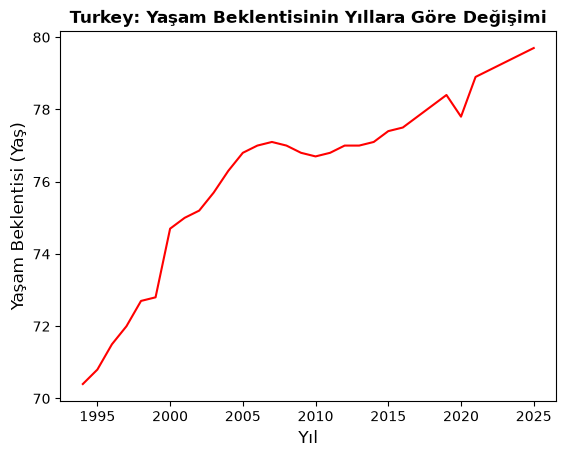

In [104]:
plt.plot(
    turkey_life_expectancy['year'], 
    turkey_life_expectancy['life expectancy'],  
    color='r', 
    linewidth=1.5)

# Grafik başlık ve eksen etiketleri
plt.title(f"{selected_country}: Yaşam Beklentisinin Yıllara Göre Değişimi", fontsize=12, fontweight='bold')
plt.xlabel("Yıl", fontsize=12)
plt.ylabel("Yaşam Beklentisi (Yaş)", fontsize=12)

plt.show()